In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import os, time, ast
import math
import pandas as pd
import numpy as np
from matplotlib.pyplot import title
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PowerTransformer

import warnings


warnings.filterwarnings('ignore')

# --- IMPOSTAZIONI GLOBALI PER I GRAFICI ---
# Stile base
plt.style.use("dark_background")
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="icefire",
    font="sans-serif",
    font_scale=1.1
)

# Aggiornamenti avanzati
plt.rcParams.update({
    # Colori e sfondi
    'figure.facecolor': '#111111',
    'axes.facecolor': '#111111',
    'savefig.facecolor': '#111111',
    'axes.edgecolor': 'white',
    'axes.labelcolor': 'white',
    'axes.titlecolor': 'white',
    'text.color': 'white',
    'xtick.color': 'lightgray',
    'ytick.color': 'lightgray',

    # Font e peso
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',

    # Griglia elegante
    'axes.grid': True,
    'grid.color': 'gray',
    'grid.linestyle': '--',
    'grid.linewidth': 0.4,
    'grid.alpha': 0.3,  # meno invasiva

    # Tick leggeri
    'xtick.direction': 'out',
    'ytick.direction': 'out',

    # Leggibilità generale
    'legend.edgecolor': 'gray',
    'legend.facecolor': '#222222',
    'legend.fontsize': 'medium',
})

print("✅ Impostazioni grafiche caricate.")

# --- CREAZIONE DIRECTORY PER I MODELLI ---
# print("--- Creazione directory per i modelli ---")
# models_dir = 'models_time_series_classification/'
# os.makedirs(models_dir, exist_ok=True)
# print(f"✅ Directory per i modelli '{models_dir}' pronta.")

# --- CREAZIONE DIRECTORY PER I PLOT ---
plots_dir = 'plots_clustering/'
os.makedirs(plots_dir, exist_ok=True)
print(f"✅ Directory per i grafici '{plots_dir}' pronta.")

# --- CARICAMENTO DEL DATASET PREPARATO ---
dataset_dir = "Dataset/"
dataset_name = "spotify_cleaned.csv"
try:
    df = pd.read_csv(os.path.join(dataset_dir, dataset_name))
    print(f"✅ Dataset preparato caricato: {df.shape[0]} righe, {df.shape[1]} colonne.")
except FileNotFoundError as e:
    print(f"❌ Errore: File non trovato. Assicurati di aver eseguito il Modulo 0 e salvato '{dataset_name}'.")
    exit(1)



✅ Impostazioni grafiche caricate.
✅ Directory per i grafici 'plots_clustering/' pronta.
✅ Dataset preparato caricato: 108299 righe, 66 colonne.


In [2]:
df.head(10)

,artists,album_name,track_name,popularity,explicit,danceability,energy,loudness,speechiness,acousticness,...,genres_10_Classical/Ambient & Stage,genres_10_Country/Folk & Songwriter,genres_10_Electronic & Dance,genres_10_Hip-Hop & R&B,genres_10_Jazz/Soul/Funk/Blues,genres_10_Latin & Brazilian,genres_10_Metal & Hardcore,genres_10_Pop & Indie,genres_10_Rock & Alternative,genres_10_World & Regional
0,Gen Hoshino,Comedy,Comedy,73,0,0.676,0.4610,-6.746,0.1430,0.0322,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,0,0.420,0.1660,-17.235,0.0763,0.9240,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,0,0.438,0.3590,-9.734,0.0557,0.2100,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,0,0.266,0.0596,-18.515,0.0363,0.9050,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Chord Overstreet,Hold On,Hold On,82,0,0.618,0.4430,-9.681,0.0526,0.4690,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,Tyrone Wells,Days I Will Remember,Days I Will Remember,58,0,0.688,0.4810,-8.807,0.1050,0.2890,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74,0,0.407,0.1470,-8.822,0.0355,0.8570,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,Jason Mraz,We Sing. We Dance. We Steal Things.,I'm Yours,80,0,0.703,0.4440,-9.331,0.0417,0.5590,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,74,0,0.625,0.4140,-8.700,0.0369,0.2940,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,Ross Copperman,Hunger,Hunger,56,0,0.442,0.6320,-6.770,0.0295,0.4260,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108299 entries, 0 to 108298
Data columns (total 66 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   artists                              108299 non-null  object 
 1   album_name                           108299 non-null  object 
 2   track_name                           108299 non-null  object 
 3   popularity                           108299 non-null  int64  
 4   explicit                             108299 non-null  int64  
 5   danceability                         108299 non-null  float64
 6   energy                               108299 non-null  float64
 7   loudness                             108299 non-null  float64
 8   speechiness                          108299 non-null  float64
 9   acousticness                         108299 non-null  float64
 10  instrumentalness                     108299 non-null  float64
 11  liveness     

#### Columns Selection for Clustering (dataset already contains columns processed)

In [7]:
columns_to_use = []
for col in df.columns:
    if col.startswith("keymode_") or col.startswith("std_") or col.startswith("genres_10_"):
        columns_to_use.append(col)


In [10]:
columns_to_use

['std_popularity',
 'std_explicit',
 'std_danceability',
 'std_energy',
 'std_loudness',
 'std_speechiness',
 'std_acousticness',
 'std_instrumentalness',
 'std_liveness',
 'std_valence',
 'std_tempo',
 'std_time_signature',
 'std_duration_mins',
 'keymode_A major',
 'keymode_A minor',
 'keymode_Ab major',
 'keymode_Ab minor',
 'keymode_B major',
 'keymode_B minor',
 'keymode_Bb major',
 'keymode_Bb minor',
 'keymode_C major',
 'keymode_C minor',
 'keymode_C# major',
 'keymode_C# minor',
 'keymode_D major',
 'keymode_D minor',
 'keymode_E major',
 'keymode_E minor',
 'keymode_Eb major',
 'keymode_Eb minor',
 'keymode_F major',
 'keymode_F minor',
 'keymode_F# major',
 'keymode_F# minor',
 'keymode_G major',
 'keymode_G minor',
 'genres_10_Classical/Ambient & Stage',
 'genres_10_Country/Folk & Songwriter',
 'genres_10_Electronic & Dance',
 'genres_10_Hip-Hop & R&B',
 'genres_10_Jazz/Soul/Funk/Blues',
 'genres_10_Latin & Brazilian',
 'genres_10_Metal & Hardcore',
 'genres_10_Pop & Indie'

In [11]:
X_scaled = df[columns_to_use].copy()

## K-means Clustering (Prototype Based)

#### Choosing the best k for k-means

In [13]:
from sklearn.cluster import KMeans

# Metodo dell'inerzia e della silhouette
inertia_list = []

k_range = range(2, 51) # 2 clusters is the minimum value for k parameter
for k in k_range:
    k_means = KMeans(n_clusters=k, init = "k-means++", n_init="auto", algorithm="elkan", random_state=42)
    k_means.fit(X_scaled)
    inertia = k_means.inertia_
    inertia_list.append(inertia)
    print(f"k={k}: inertia={inertia}")
#end_for


k=2: inertia=1355811.5888684145
k=3: inertia=1264373.353918991
k=4: inertia=1158858.7078545017
k=5: inertia=1096597.5107705137
k=6: inertia=1045364.4112397808
k=7: inertia=991939.1575834791
k=8: inertia=957988.4035582478
k=9: inertia=909354.5676561343
k=10: inertia=879456.3588433429
k=11: inertia=866178.0865425834
k=12: inertia=847314.5009051743
k=13: inertia=836545.4442539505
k=14: inertia=823009.0995903759
k=15: inertia=809039.844314183
k=16: inertia=793352.6513419707
k=17: inertia=782564.8423854426
k=18: inertia=772786.2598391934
k=19: inertia=764944.2668913169
k=20: inertia=743268.1607740214
k=21: inertia=738003.446516118
k=22: inertia=731680.742216002
k=23: inertia=721921.2922180898
k=24: inertia=700790.4768077997
k=25: inertia=695589.5352068455
k=26: inertia=689310.385038942
k=27: inertia=684324.8909912972
k=28: inertia=683676.3946158383
k=29: inertia=674751.5511997058
k=30: inertia=670032.6931912567
k=31: inertia=667510.6354003099
k=32: inertia=662314.4012321972
k=33: inertia=65

#### Displaying Inertia curve

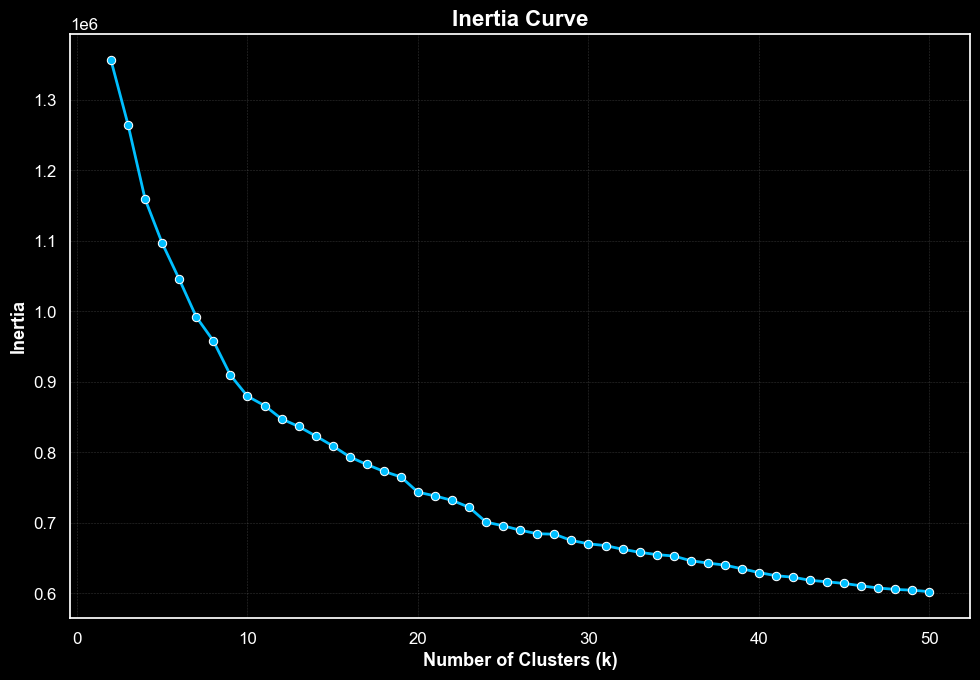

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Tema scuro per DataSpell o ambienti dark
plt.style.use("dark_background")

# Stile e grafico
plt.figure(figsize=(10, 7))

sns.lineplot(
    x=list(range(2, len(inertia_list) + 2)),
    y=inertia_list,
    linewidth=2,
    marker="o",
    markersize=6,
    markerfacecolor="deepskyblue",
    markeredgecolor="white",
    color="deepskyblue"
)

# Titoli e labels
plt.title("Inertia Curve", fontsize=16, fontweight='bold')
plt.xlabel("Number of Clusters (k)", fontsize=13)
plt.ylabel("Inertia", fontsize=13)

# Griglia elegante
plt.grid(True, linestyle="--", alpha=0.2)

# Spaziatura e salvataggio
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "inertia_curve.png"), dpi=300, bbox_inches="tight")
plt.show()

"""
il gomito è per k=10
"""


#### Metodo della Silhouette

In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = {}
local_maxima = {}

k_range = range(2, 31)

# Step 1: Calcolo silhouette
for k in k_range:
    k_means = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init="auto",
        algorithm="elkan",
        random_state=42
    )
    labels = k_means.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=20000,
        random_state=42
    )
    silhouette_scores[k] = score
    print(f"k={k}: silhouette = {score:.4f}")

# Step 2: Trova massimi locali
k_values = list(silhouette_scores.keys())
scores = list(silhouette_scores.values())

for i in range(1, len(scores) - 1):
    prev_s = scores[i - 1]
    curr_s = scores[i]
    next_s = scores[i + 1]
    k_curr = k_values[i]

    if curr_s > prev_s and curr_s > next_s:
        local_maxima[k_curr] = curr_s
        print(f"➤ Massimo relativo a k={k_curr}: silhouette = {curr_s:.4f}")
# end_for

"""
➤ Massimo relativo a k=4: silhouette = 0.1098
➤ Massimo relativo a k=7: silhouette = 0.1197
➤ Massimo relativo a k=9: silhouette = 0.1233
➤ Massimo relativo a k=14: silhouette = 0.1035
➤ Massimo relativo a k=20: silhouette = 0.0884
➤ Massimo relativo a k=24: silhouette = 0.0940
➤ Massimo relativo a k=29: silhouette = 0.0847

Dai massimi relativi si vede subito che per k=9 si ha il miglior compromesso
"""


k=2: silhouette = 0.1864
k=3: silhouette = 0.0993
k=4: silhouette = 0.1098
k=5: silhouette = 0.1098
k=6: silhouette = 0.1178
k=7: silhouette = 0.1197
k=8: silhouette = 0.1154
k=9: silhouette = 0.1233
k=10: silhouette = 0.1127
k=11: silhouette = 0.1122
k=12: silhouette = 0.1059
k=13: silhouette = 0.1029
k=14: silhouette = 0.1035
k=15: silhouette = 0.0977
k=16: silhouette = 0.0970
k=17: silhouette = 0.0942
k=18: silhouette = 0.0911
k=19: silhouette = 0.0859
k=20: silhouette = 0.0884
k=21: silhouette = 0.0840
k=22: silhouette = 0.0832
k=23: silhouette = 0.0898
k=24: silhouette = 0.0940
k=25: silhouette = 0.0900
k=26: silhouette = 0.0891
k=27: silhouette = 0.0871
k=28: silhouette = 0.0840
k=29: silhouette = 0.0847
k=30: silhouette = 0.0822
➤ Massimo relativo a k=4: silhouette = 0.1098
➤ Massimo relativo a k=7: silhouette = 0.1197
➤ Massimo relativo a k=9: silhouette = 0.1233
➤ Massimo relativo a k=14: silhouette = 0.1035
➤ Massimo relativo a k=20: silhouette = 0.0884
➤ Massimo relativo a k

#### displaying silhouette curve

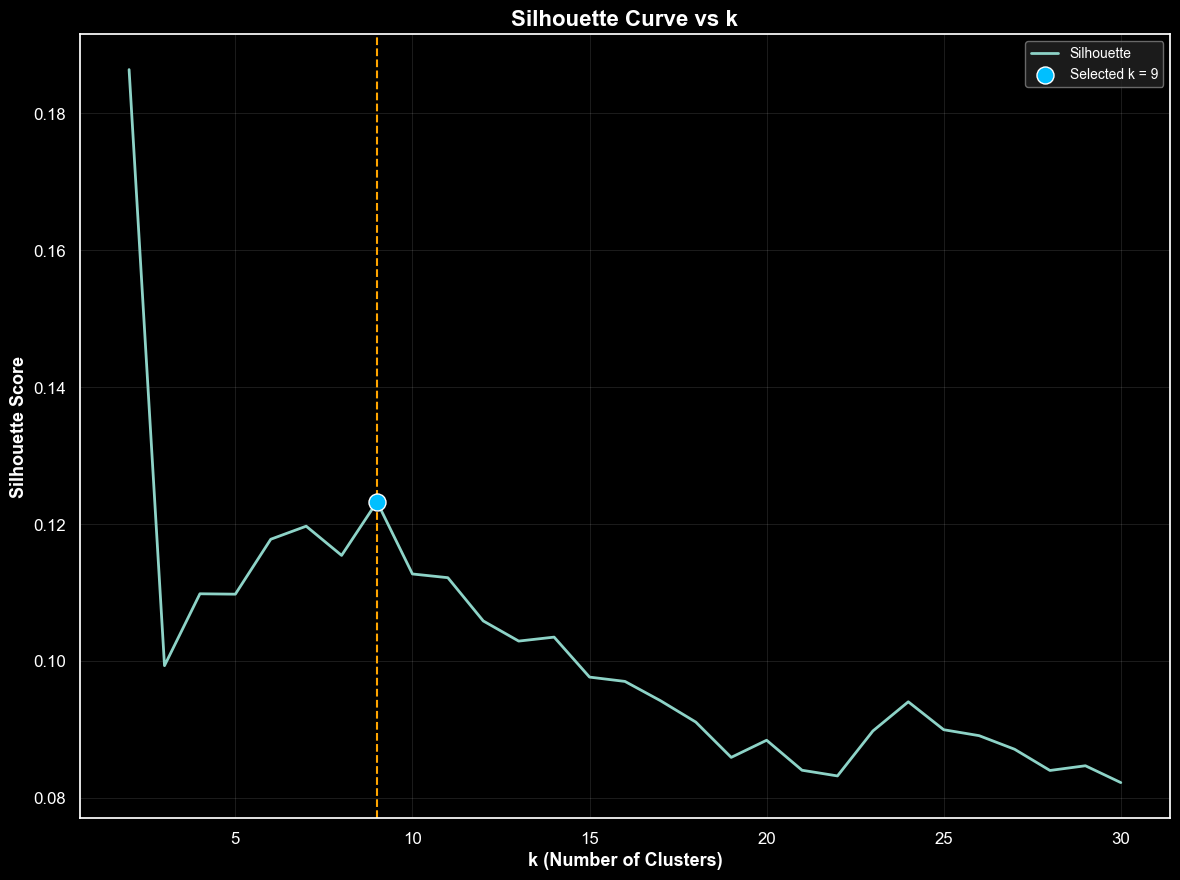

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

k_optimal = 9

plt.figure(figsize=(12, 9))
# Curva silhouette
sns.lineplot(x=list(silhouette_scores.keys()), y=list(silhouette_scores.values()), label="Silhouette", lw=2)

# Punto evidenziato solo per k ottimale scelto
plt.scatter(
    k_optimal,
    silhouette_scores[k_optimal],
    color="deepskyblue",
    edgecolor="white",
    s=150,
    zorder=6,
    label=f"Selected k = {k_optimal}"
)

# Linea verticale su k ottimale
plt.axvline(x=k_optimal, color="orange", linestyle="--", lw=1.5)

# Titoli ed etichette
plt.title("Silhouette Curve vs k", fontsize=16)
plt.xlabel("k (Number of Clusters)", fontsize=13)
plt.ylabel("Silhouette Score", fontsize=13)
plt.legend(loc="best", fontsize=10)
plt.grid(True, alpha=0.2)

# Salva e mostra
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "silhouette_curve.png"), dpi=300, bbox_inches="tight")
plt.show()


#### K-MEANS with optimal k = 5

<Axes: xlabel='kmeans_labels', ylabel='count'>

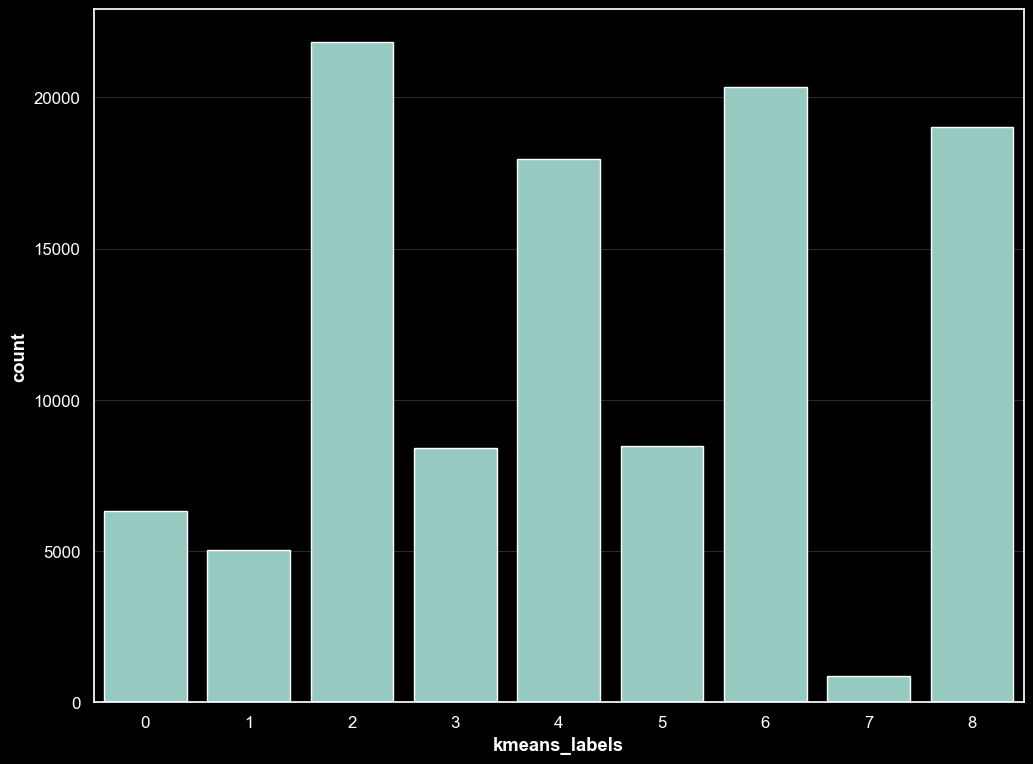

In [55]:
OPTIMAL_K = 9
kmeans = KMeans(
    n_clusters=OPTIMAL_K,
    init = "k-means++",
    n_init="auto",
    algorithm="elkan",
    random_state=42
)
kmeans_labels = kmeans.fit_predict(X_scaled)
df["kmeans_labels"] = kmeans_labels
X_scaled["kmeans_labels"] = kmeans_labels

# Controlliamo la sparsità dei clusters
X_scaled["kmeans_labels"].value_counts()

# disegnamo un countplot
plt.figure(figsize=(12, 9))
sns.countplot(x="kmeans_labels", data=df)



#### Displaying Clusters in 2D using PCA

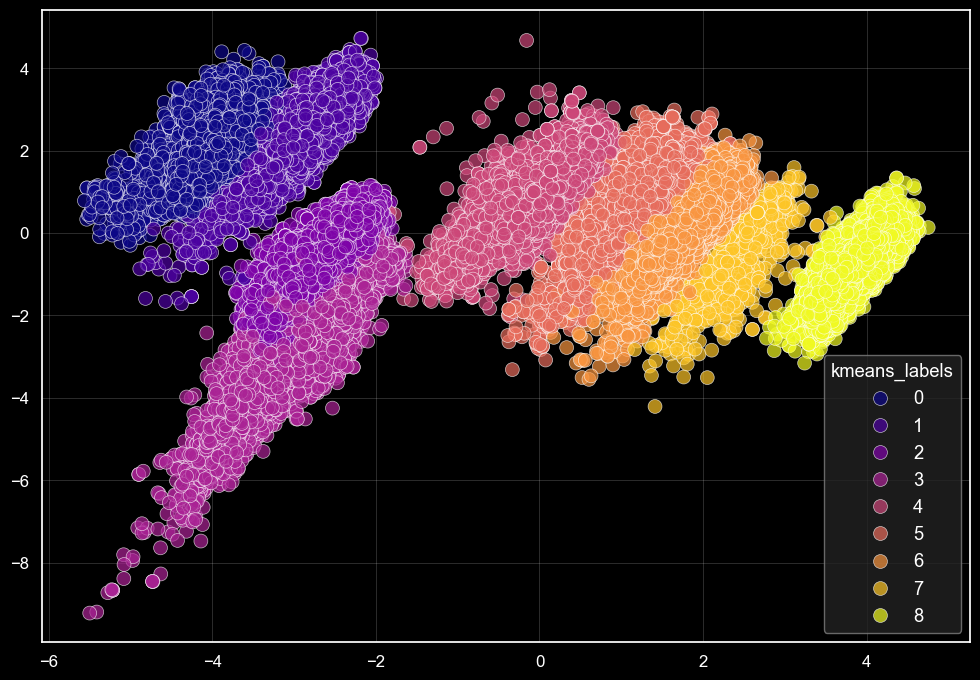

In [56]:
from sklearn.decomposition import PCA # Principal Component Analysis
pca_2d = PCA(n_components=2, random_state=42)
X_2D = pca_2d.fit_transform(X_scaled)

# Displaying Clusters in 2D
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_2D[:, 0],
    y=X_2D[:, 1],
    hue=X_scaled["kmeans_labels"],
    palette="plasma",
    alpha=0.7,
    s=100,
    edgecolor="white",
    linewidth=0.5,
    legend="full"
)
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "clusters_2d.png"), dpi=300, bbox_inches="tight")
plt.show()


### Displaying Clusters in 3D using t-SNE

In [58]:
pca_3d = PCA(n_components=3, random_state=42)
X_3D = pca_3d.fit_transform(X_scaled)

#### Plotting the clusters in 3D

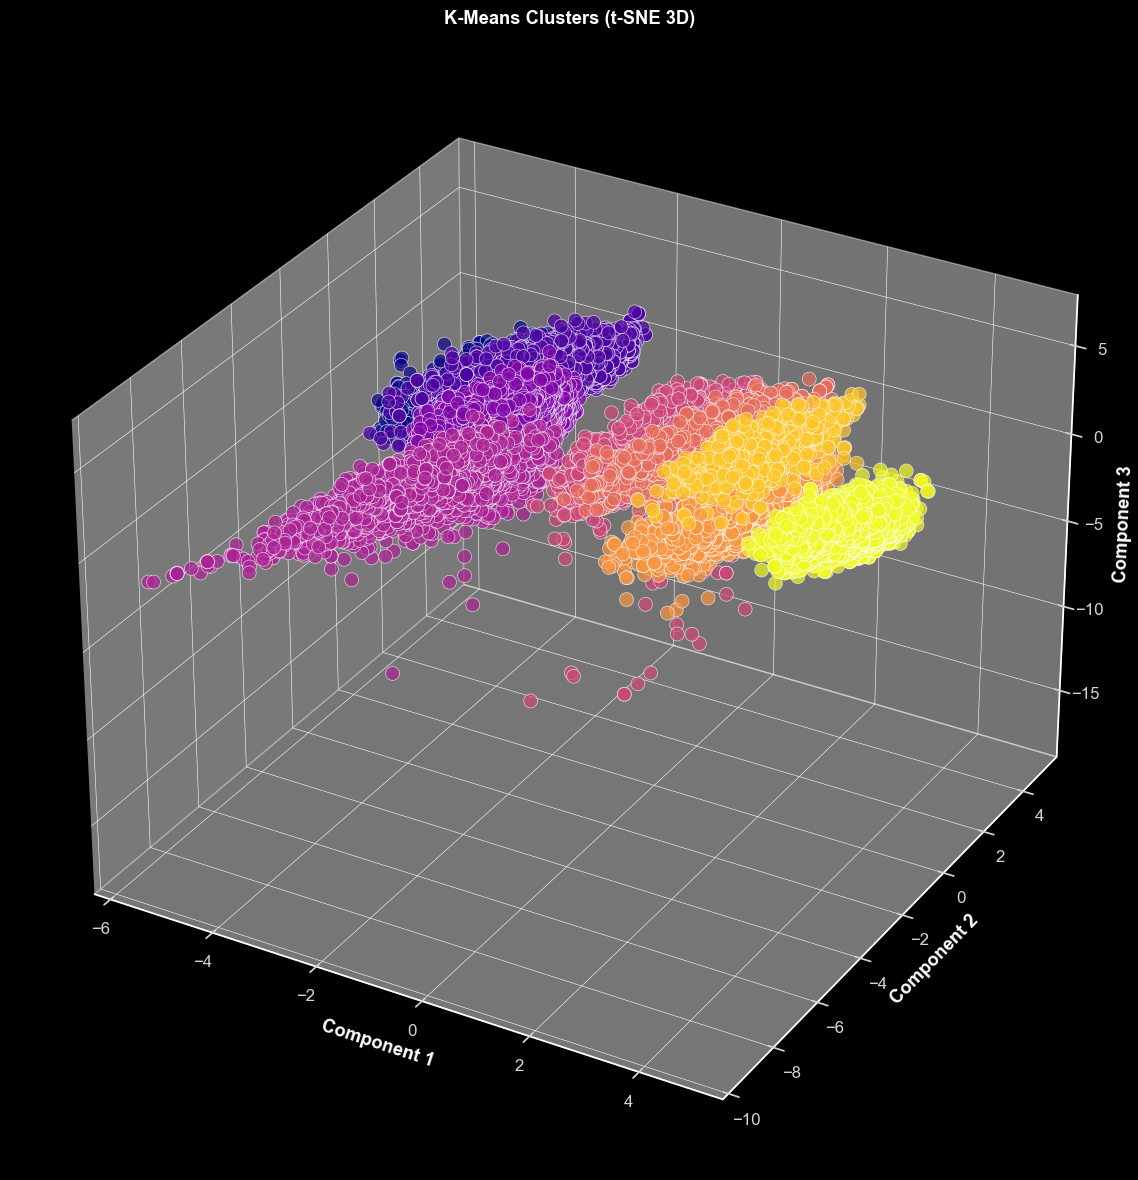

In [59]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import os

fig = plt.figure(figsize=(15, 12))
ax = fig.add_subplot(111, projection='3d')

# Scatter 3D
p = ax.scatter(
    X_3D[:, 0],
    X_3D[:, 1],
    X_3D[:, 2],
    c=df["kmeans_labels"],
    cmap="plasma",
    alpha=0.7,
    s=100,
    edgecolors='white',
    linewidths=0.5
)

# Titoli e assi in bianco per tema scuro
ax.set_title("K-Means Clusters (t-SNE 3D)", color='white', pad=20)
ax.set_xlabel("Component 1", color='white')
ax.set_ylabel("Component 2", color='white')
ax.set_zlabel("Component 3", color='white')

# Tick colorati
ax.tick_params(colors='lightgray')

# Sfondo scuro
ax.set_facecolor('black')        # background dei pannelli 3D
fig.patch.set_facecolor('black') # background generale

# Legenda personalizzata (opzionale)
# unique_labels = df["kmeans_labels"].unique()
# ax.legend(...)

plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "clusters_3d.png"), dpi=300, bbox_inches="tight")
plt.show()


### Proviamo a classificare su questi incredibili clusters cosi coesi!

In [61]:
X_clf = X_scaled.drop(columns=["kmeans_labels"]).copy()
y_target = X_scaled["kmeans_labels"].copy()


In [62]:
X_train, X_test, y_train, y_test = train_test_split(X_clf, y_target, test_size=0.3, stratify=y_target, random_state=42)

### RETE NEURALE Keras, la alleno velocemente con la GPU del Mac Studio M3 Ultra con 80 cores...

In [65]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Build model con architettura ottimizzata per 9 cluster
model = models.Sequential([
   layers.Dense(512, activation='swish', input_shape=(X_train.shape[1],)),
   layers.BatchNormalization(),
   layers.Dropout(0.4),

   layers.Dense(256, activation='swish'),
   layers.BatchNormalization(),
   layers.Dropout(0.3),

   layers.Dense(128, activation='swish'),
   layers.BatchNormalization(),
   layers.Dropout(0.25),

   layers.Dense(64, activation='swish'),
   layers.BatchNormalization(),
   layers.Dropout(0.2),

   layers.Dense(32, activation='relu'),
   layers.Dense(9, activation='softmax')  # 9 cluster invece di 3
])

# Optimizer con weight decay per regolarizzazione
optimizer = tf.keras.optimizers.AdamW(
   learning_rate=0.001,
   weight_decay=0.0001
)

model.compile(
   optimizer=optimizer,
   loss='sparse_categorical_crossentropy',
   metrics=['accuracy', tf.keras.metrics.SparseCategoricalAccuracy()]
)

# Callbacks avanzati
callbacks = [
   EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),  # Più patience per 9 classi
   ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6, verbose=1),
   ModelCheckpoint('best_model_9clusters.keras', save_best_only=True, monitor='val_accuracy', mode='max')
]

# Training con class weights per 9 classi
from sklearn.utils.class_weight import compute_class_weight
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {i: w for i, w in enumerate(class_weights)}

print(f"Training for {len(np.unique(y_train))} clusters")
print(f"Class weights: {class_weight_dict}")

history = model.fit(
   X_train, y_train,
   validation_split=0.2,
   epochs=100,  # Più epoche per task più complesso
   batch_size=512,  # Batch più grande per stabilità
   callbacks=callbacks,
   class_weight=class_weight_dict,
   verbose=1
)

# Evaluation completa
test_loss, test_acc, test_sparse_acc = model.evaluate(X_test, y_test)
print(f"\nTest Accuracy: {test_acc:.4f}")

# Predictions e report per 9 cluster
y_pred = model.predict(X_test).argmax(axis=1)
cluster_names = [f'Cluster {i}' for i in range(9)]

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=cluster_names))

# Matrice di confusione
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)


Training for 9 clusters
Class weights: {0: 1.8992609294751346, 1: 2.394321268397448, 2: 0.5513662513727972, 3: 1.4293606350283765, 4: 0.6699452972418851, 5: 1.4182896484630783, 6: 0.591767754828033, 7: 13.696296296296296, 8: 0.6321367521367521}
Epoch 1/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - accuracy: 0.6220 - loss: 1.0067 - sparse_categorical_accuracy: 0.6220 - val_accuracy: 0.7026 - val_loss: 0.8626 - val_sparse_categorical_accuracy: 0.7026 - learning_rate: 0.0010
Epoch 2/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.8823 - loss: 0.2616 - sparse_categorical_accuracy: 0.8823 - val_accuracy: 0.8151 - val_loss: 0.4726 - val_sparse_categorical_accuracy: 0.8151 - learning_rate: 0.0010
Epoch 3/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.9027 - loss: 0.2184 - sparse_categorical_accuracy: 0.9027 - val_accuracy: 0.9290 - val_loss: 0.1899 - val_sparse_categorical_accuracy: 0.9290 - learning_rate: 0.0010
Epoch 4/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step

### Displaying Classification Metrics

1016/1016 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


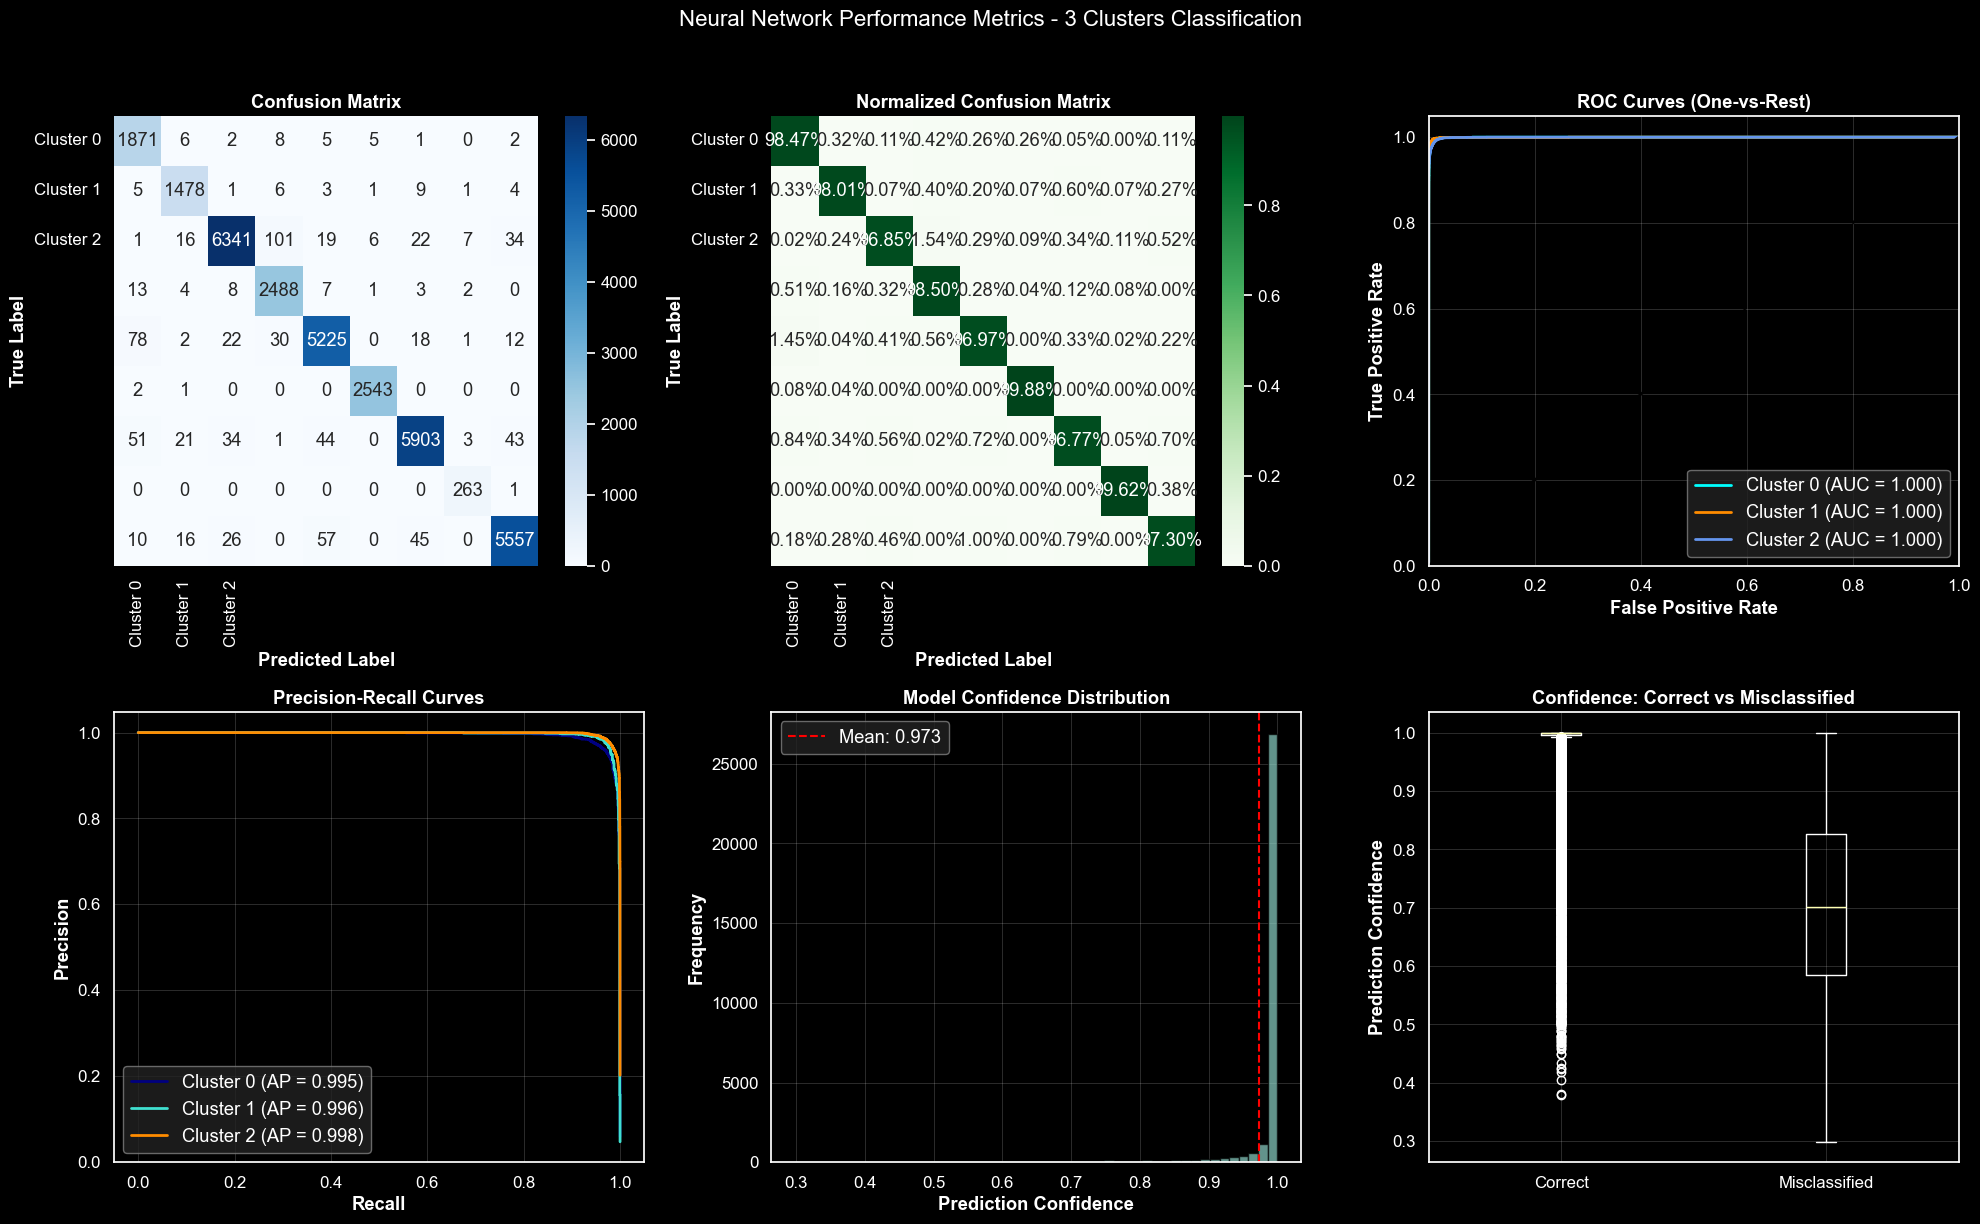


ADVANCED PERFORMANCE METRICS

📊 OVERALL METRICS:
Accuracy:              0.9747
Balanced Accuracy:     0.9804
Cohen's Kappa:         0.9702
Matthews Corr Coef:    0.9703
Log Loss:              0.0668
Mean Confidence:       0.9729
Std Confidence:        0.0820

📈 PER-CLASS METRICS:

Cluster 0:
  Accuracy:    0.9847
  ROC-AUC:     0.9996
  Avg Precision: 0.9946
  Avg Confidence: 0.9831

Cluster 1:
  Accuracy:    0.9801
  ROC-AUC:     0.9996
  Avg Precision: 0.9961
  Avg Confidence: 0.9822

Cluster 2:
  Accuracy:    0.9685
  ROC-AUC:     0.9995
  Avg Precision: 0.9983
  Avg Confidence: 0.9690

❌ MISCLASSIFICATION ANALYSIS:
Total errors: 821 / 32490 (2.53%)
Avg confidence on errors: 0.7103
  Cluster 0 → 1: 6 errors
  Cluster 0 → 2: 2 errors
  Cluster 1 → 0: 5 errors
  Cluster 1 → 2: 1 errors
  Cluster 2 → 0: 1 errors
  Cluster 2 → 1: 16 errors

📊 STATISTICAL TESTS:
Model significantly better than random? True
Confidence interval (95%): [0.6647, 1.0000]



In [66]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
   confusion_matrix, classification_report, roc_curve, auc,
   precision_recall_curve, average_precision_score,
   cohen_kappa_score, matthews_corrcoef, log_loss,
   f1_score, balanced_accuracy_score
)
from sklearn.preprocessing import label_binarize
from itertools import cycle

# Predictions (già calcolate dal modello)
y_pred_proba = model.predict(X_test)
y_pred = np.argmax(y_pred_proba, axis=1)

# Setup figure
fig = plt.figure(figsize=(20, 12))
fig.suptitle('Neural Network Performance Metrics - 3 Clusters Classification', fontsize=16, y=1.02)

# 1. CONFUSION MATRIX
ax1 = plt.subplot(2, 3, 1)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2'],
           yticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2'])
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

# 2. NORMALIZED CONFUSION MATRIX
ax2 = plt.subplot(2, 3, 2)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens',
           xticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2'],
           yticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2'])
plt.title('Normalized Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

# 3. ROC CURVES (One-vs-Rest)
ax3 = plt.subplot(2, 3, 3)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
   fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_proba[:, i])
   roc_auc[i] = auc(fpr[i], tpr[i])

colors = cycle(['aqua', 'darkorange', 'cornflowerblue'])
for i, color in zip(range(n_classes), colors):
   plt.plot(fpr[i], tpr[i], color=color, lw=2,
            label=f'Cluster {i} (AUC = {roc_auc[i]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves (One-vs-Rest)')
plt.legend(loc="lower right")

# 4. PRECISION-RECALL CURVES
ax4 = plt.subplot(2, 3, 4)
precision = dict()
recall = dict()
average_precision = dict()
for i in range(n_classes):
   precision[i], recall[i], _ = precision_recall_curve(y_test_bin[:, i], y_pred_proba[:, i])
   average_precision[i] = average_precision_score(y_test_bin[:, i], y_pred_proba[:, i])

colors = cycle(['navy', 'turquoise', 'darkorange'])
for i, color in zip(range(n_classes), colors):
   plt.plot(recall[i], precision[i], color=color, lw=2,
            label=f'Cluster {i} (AP = {average_precision[i]:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves')
plt.legend(loc="lower left")
plt.grid(True, alpha=0.3)

# 5. CONFIDENCE DISTRIBUTION
ax5 = plt.subplot(2, 3, 5)
max_probs = np.max(y_pred_proba, axis=1)
plt.hist(max_probs, bins=50, edgecolor='black', alpha=0.7)
plt.axvline(x=np.mean(max_probs), color='red', linestyle='--',
           label=f'Mean: {np.mean(max_probs):.3f}')
plt.xlabel('Prediction Confidence')
plt.ylabel('Frequency')
plt.title('Model Confidence Distribution')
plt.legend()
plt.grid(True, alpha=0.3)

# 6. ERROR ANALYSIS
ax6 = plt.subplot(2, 3, 6)
misclassified = y_test != y_pred
misclass_confidence = max_probs[misclassified]
correct_confidence = max_probs[~misclassified]

if len(misclass_confidence) > 0:
   plt.boxplot([correct_confidence, misclass_confidence],
               labels=['Correct', 'Misclassified'])
   plt.ylabel('Prediction Confidence')
   plt.title('Confidence: Correct vs Misclassified')
else:
   plt.text(0.5, 0.5, 'No Misclassifications!',
            ha='center', va='center', fontsize=20)
   plt.title('Perfect Classification')
   plt.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "nn_performance_metrics.png"), dpi=300, bbox_inches="tight")
plt.show()

# ADVANCED METRICS REPORT
print("\n" + "="*70)
print("ADVANCED PERFORMANCE METRICS")
print("="*70)

# Overall metrics
print("\n📊 OVERALL METRICS:")
print(f"Accuracy:              {np.mean(y_pred == y_test):.4f}")
print(f"Balanced Accuracy:     {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Cohen's Kappa:         {cohen_kappa_score(y_test, y_pred):.4f}")
print(f"Matthews Corr Coef:    {matthews_corrcoef(y_test, y_pred):.4f}")
print(f"Log Loss:              {log_loss(y_test, y_pred_proba):.4f}")
print(f"Mean Confidence:       {np.mean(max_probs):.4f}")
print(f"Std Confidence:        {np.std(max_probs):.4f}")

# Per-class metrics
print("\n📈 PER-CLASS METRICS:")
for i in range(n_classes):
   class_mask = y_test == i
   class_accuracy = np.mean(y_pred[class_mask] == i)
   class_confidence = np.mean(max_probs[class_mask])
   print(f"\nCluster {i}:")
   print(f"  Accuracy:    {class_accuracy:.4f}")
   print(f"  ROC-AUC:     {roc_auc[i]:.4f}")
   print(f"  Avg Precision: {average_precision[i]:.4f}")
   print(f"  Avg Confidence: {class_confidence:.4f}")

# Misclassification analysis
print("\n❌ MISCLASSIFICATION ANALYSIS:")
n_errors = np.sum(misclassified)
print(f"Total errors: {n_errors} / {len(y_test)} ({n_errors/len(y_test)*100:.2f}%)")
if n_errors > 0:
   print(f"Avg confidence on errors: {np.mean(misclass_confidence):.4f}")
   for i in range(n_classes):
       for j in range(n_classes):
           if i != j:
               errors = cm[i, j]
               if errors > 0:
                   print(f"  Cluster {i} → {j}: {errors} errors")

# Statistical significance
print("\n📊 STATISTICAL TESTS:")
print(f"Model significantly better than random? {np.mean(y_pred == y_test) > 1/n_classes}")
print(f"Confidence interval (95%): [{np.percentile(max_probs, 2.5):.4f}, {np.percentile(max_probs, 97.5):.4f}]")

print("\n" + "="*70)


#### Single Decision Tree: Validating the Cohesiveness of Our Clusters

In [67]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import warnings
warnings.filterwarnings('ignore')

print("="*70)
print("DECISION TREE CLASSIFIER - HYPERPARAMETER OPTIMIZATION")
print("="*70)

# Define parameter grid for exhaustive search
param_grid = {
   'max_depth': [10, 15, 20, 30, None],
   'min_samples_split': [2, 5, 7, 10, 15, 20, 30],
   'min_samples_leaf': [1, 2, 5, 7, 10, 15, 20],
   'criterion': ['gini', 'entropy'],
   'splitter': ['best', 'random'],
   'max_features': ['sqrt', 'log2', None]
}

# Initialize base model
dt_base = DecisionTreeClassifier(random_state=42)

# Setup cross-validation strategy
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Grid search with cross-validation
print("\n⚙️ Running Grid Search...")
grid_search = GridSearchCV(
   estimator=dt_base,
   param_grid=param_grid,
   cv=cv_strategy,
   scoring='accuracy',
   n_jobs=-1,
   verbose=1,
   return_train_score=True
)

# Fit grid search
grid_search.fit(X_train, y_train)

# Best parameters
print("\n✅ BEST PARAMETERS:")
for param, value in grid_search.best_params_.items():
   print(f"  {param:20s}: {value}")
print(f"\n  Best CV Score: {grid_search.best_score_:.4f}")

# Train final model with best parameters
dt_final = grid_search.best_estimator_

# Cross-validation scores on training set
cv_scores = cross_val_score(dt_final, X_train, y_train, cv=cv_strategy, scoring='accuracy')
print(f"\n📊 CROSS-VALIDATION RESULTS (5-fold):")
print(f"  Mean Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"  Individual Folds: {cv_scores}")

# Predictions
y_pred_train = dt_final.predict(X_train)
y_pred_test = dt_final.predict(X_test)

# Training vs Test Performance
print(f"\n🎯 PERFORMANCE METRICS:")
print(f"  Training Accuracy: {accuracy_score(y_train, y_pred_train):.4f}")
print(f"  Test Accuracy:     {accuracy_score(y_test, y_pred_test):.4f}")
print(f"  Overfitting Gap:   {accuracy_score(y_train, y_pred_train) - accuracy_score(y_test, y_pred_test):.4f}")

# Feature importance
feature_importance = pd.DataFrame({
   'feature': X_train.columns,
   'importance': dt_final.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\n🔍 TOP 10 MOST IMPORTANT FEATURES:")
for idx, row in feature_importance.head(10).iterrows():
   print(f"  {row['feature']:30s}: {row['importance']:.4f}")

# Detailed classification report
print("\n📋 CLASSIFICATION REPORT (Test Set):")
print(classification_report(y_test, y_pred_test,
                         target_names=[f'Cluster {i}' for i in range(9)],
                         digits=4))

# Tree statistics
print(f"\n🌳 TREE STATISTICS:")
print(f"  Tree Depth:        {dt_final.get_depth()}")
print(f"  Number of Leaves: {dt_final.get_n_leaves()}")
print(f"  Total Nodes:      {dt_final.tree_.node_count}")



DECISION TREE CLASSIFIER - HYPERPARAMETER OPTIMIZATION

⚙️ Running Grid Search...
Fitting 5 folds for each of 2940 candidates, totalling 14700 fits

✅ BEST PARAMETERS:
  criterion           : entropy
  max_depth           : 20
  max_features        : None
  min_samples_leaf    : 1
  min_samples_split   : 2
  splitter            : best

  Best CV Score: 0.9210

📊 CROSS-VALIDATION RESULTS (5-fold):
  Mean Accuracy: 0.9210 ± 0.0014
  Individual Folds: [0.91861232 0.92078881 0.92303126 0.92098668 0.92137722]

🎯 PERFORMANCE METRICS:
  Training Accuracy: 0.9997
  Test Accuracy:     0.9258
  Overfitting Gap:   0.0738

🔍 TOP 10 MOST IMPORTANT FEATURES:
  std_energy                    : 0.1757
  std_instrumentalness          : 0.1386
  std_explicit                  : 0.1353
  std_popularity                : 0.1116
  std_danceability              : 0.1015
  std_liveness                  : 0.0859
  std_acousticness              : 0.0765
  std_valence                   : 0.0653
  std_loudness     

#### Displaying Decision Tree metrics

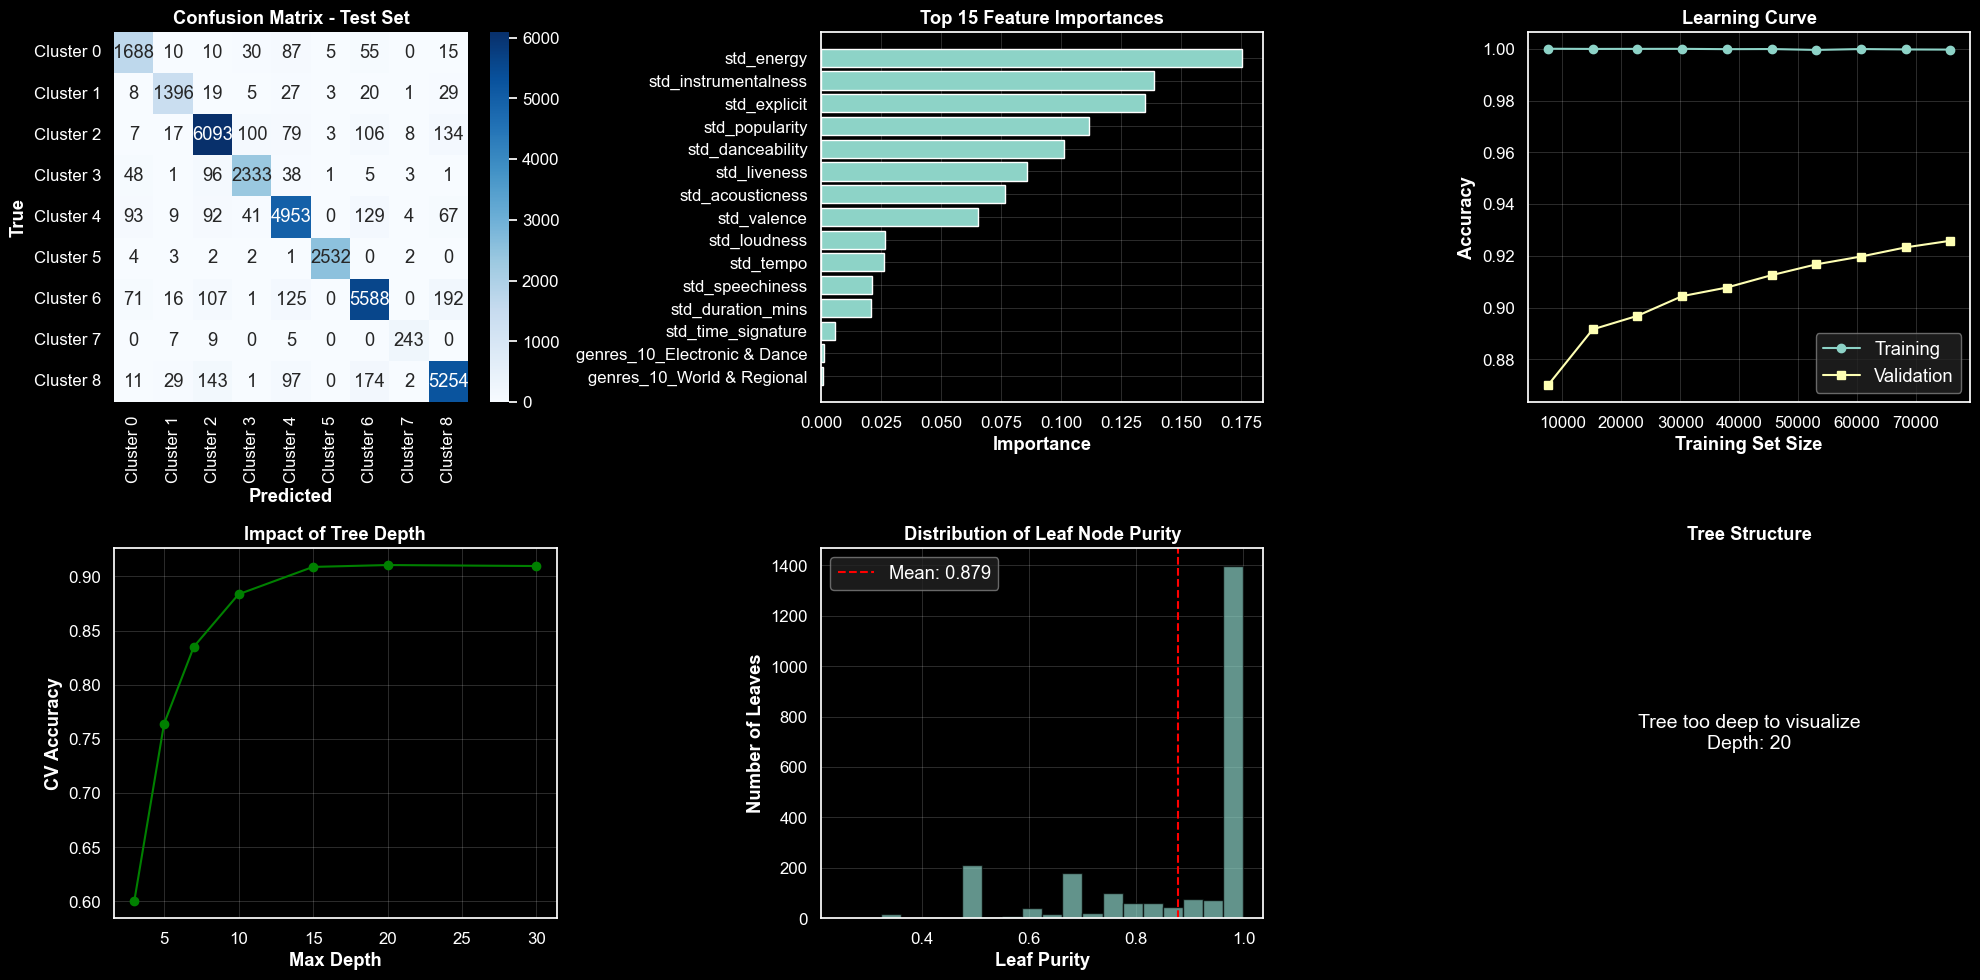

In [70]:
# Visualization
fig = plt.figure(figsize=(20, 10))

# Subplot 1: Confusion Matrix
ax1 = plt.subplot(2, 3, 1)
cm = confusion_matrix(y_test, y_pred_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=[f'Cluster {i}' for i in range(9)],
           yticklabels=[f'Cluster {i}' for i in range(9)])
plt.title('Confusion Matrix - Test Set')
plt.ylabel('True')
plt.xlabel('Predicted')

# Subplot 2: Feature Importance
ax2 = plt.subplot(2, 3, 2)
top_features = feature_importance.head(15)
plt.barh(range(len(top_features)), top_features['importance'].values)
plt.yticks(range(len(top_features)), top_features['feature'].values)
plt.xlabel('Importance')
plt.title('Top 15 Feature Importances')
plt.gca().invert_yaxis()

# Subplot 3: Learning Curve
ax3 = plt.subplot(2, 3, 3)
train_sizes = np.linspace(0.1, 1.0, 10)
train_scores = []
test_scores = []
for size in train_sizes:
   n_samples = int(size * len(X_train))
   X_subset = X_train[:n_samples]
   y_subset = y_train[:n_samples]
   dt_temp = DecisionTreeClassifier(**grid_search.best_params_, random_state=42)
   dt_temp.fit(X_subset, y_subset)
   train_scores.append(dt_temp.score(X_subset, y_subset))
   test_scores.append(dt_temp.score(X_test, y_test))

plt.plot(train_sizes * len(X_train), train_scores, 'o-', label='Training')
plt.plot(train_sizes * len(X_train), test_scores, 's-', label='Validation')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve')
plt.legend()
plt.grid(True, alpha=0.3)

# Subplot 4: Parameter Impact - Max Depth
ax4 = plt.subplot(2, 3, 4)
depths = [3, 5, 7, 10, 15, 20, 30]
depth_scores = []
for depth in depths:
   dt_temp = DecisionTreeClassifier(max_depth=depth, random_state=42)
   scores = cross_val_score(dt_temp, X_train, y_train, cv=3)
   depth_scores.append(scores.mean())
plt.plot(depths, depth_scores, 'o-', color='green')
plt.xlabel('Max Depth')
plt.ylabel('CV Accuracy')
plt.title('Impact of Tree Depth')
plt.grid(True, alpha=0.3)

# Subplot 5: Class Distribution in Leaves
ax5 = plt.subplot(2, 3, 5)
leaf_indices = dt_final.apply(X_test)
unique_leaves = np.unique(leaf_indices)
leaf_purities = []
for leaf in unique_leaves:
   leaf_samples = y_test[leaf_indices == leaf]
   if len(leaf_samples) > 0:
       purity = np.max(np.bincount(leaf_samples)) / len(leaf_samples)
       leaf_purities.append(purity)
plt.hist(leaf_purities, bins=20, edgecolor='black', alpha=0.7)
plt.xlabel('Leaf Purity')
plt.ylabel('Number of Leaves')
plt.title('Distribution of Leaf Node Purity')
plt.axvline(np.mean(leaf_purities), color='red', linestyle='--',
          label=f'Mean: {np.mean(leaf_purities):.3f}')
plt.legend()

# Subplot 6: Decision Tree Visualization (simplified)
ax6 = plt.subplot(2, 3, 6)
if dt_final.get_depth() <= 5:
   plot_tree(dt_final,
             feature_names=X_train.columns[:5],  # Show only first 5 for readability
             class_names=[f'Cluster {i}' for i in range(9)],
             filled=True,
             rounded=True,
             fontsize=8,
             max_depth=3,  # Limit depth for visualization
             ax=ax6)
   plt.title('Decision Tree Structure (Depth ≤ 3)')
else:
   ax6.text(0.5, 0.5, f'Tree too deep to visualize\nDepth: {dt_final.get_depth()}',
           ha='center', va='center', fontsize=14)
   plt.title('Tree Structure')
   ax6.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "decision_tree_analysis.png"), dpi=300, bbox_inches="tight")
plt.show()


#### Comparison with neural network

In [71]:
# Comparison with Neural Network
print("\n" + "="*70)
print("COMPARISON: Decision Tree vs Neural Network")
print("="*70)
print(f"Decision Tree Test Accuracy: {accuracy_score(y_test, y_pred_test):.4f}")
print(f"Neural Network Test Accuracy: 0.9900")  # From your previous results
print(f"Difference: {0.99 - accuracy_score(y_test, y_pred_test):.4f}")
print("\n✨ Decision Tree Advantages:")
print("  - Interpretable (see feature importance)")
print("  - No scaling required")
print("  - Fast training and inference")
print("  - Can capture non-linear boundaries")
print("\n⚠️ Decision Tree Limitations:")
print("  - Prone to overfitting")
print("  - Less stable than ensemble methods")
print("  - Single tree may not capture complex patterns")
print("="*70)


COMPARISON: Decision Tree vs Neural Network
Decision Tree Test Accuracy: 0.9258
Neural Network Test Accuracy: 0.9900
Difference: 0.0642

✨ Decision Tree Advantages:
  - Interpretable (see feature importance)
  - No scaling required
  - Fast training and inference
  - Can capture non-linear boundaries

⚠️ Decision Tree Limitations:
  - Prone to overfitting
  - Less stable than ensemble methods
  - Single tree may not capture complex patterns


#### I wanna also try SVM with Infinite Kernel (Gaussian...)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score
from sklearn.preprocessing import StandardScaler
import time
import warnings
warnings.filterwarnings('ignore')

print("="*70)
print("SUPPORT VECTOR MACHINE - RBF KERNEL OPTIMIZATION")
print("="*70)


X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

print("\n📊 Data scaling completed (essential for RBF kernel)")
print(f"   Training samples: {X_train_scaled.shape}")
print(f"   Test samples: {X_test_scaled.shape}")

# Pragmatic parameter grid - not exhaustive but effective
param_grid = {
   'C': [0.1, 1, 10, 100],  # Regularization
   'gamma': ['scale', 'auto', 0.001, 0.01, 0.1],  # RBF kernel coefficient
   'class_weight': [None, 'balanced'],  # Handle imbalanced clusters
}

print(f"\n🔍 Grid Search Space: {len(param_grid['C']) * len(param_grid['gamma']) * len(param_grid['class_weight'])} combinations")

# Base SVM with RBF (Gaussian) kernel - "infinite dimensional" feature space
svm_base = SVC(
   kernel='rbf',  # Radial Basis Function - maps to infinite dimensions
   probability=True,  # Enable probability estimates
   random_state=42,
   cache_size=500,  # MB of memory for kernel cache
   decision_function_shape='ovr'  # One-vs-Rest for multiclass
)

# Cross-validation strategy
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)  # 3-fold is pragmatic for SVM

# Grid search
print("\n⚙️ Running Grid Search (this may take a few minutes)...")
start_time = time.time()

grid_search = GridSearchCV(
   estimator=svm_base,
   param_grid=param_grid,
   cv=cv_strategy,
   scoring='accuracy',
   n_jobs=-1,
   verbose=1,
   return_train_score=True
)

grid_search.fit(X_train_scaled, y_train)
search_time = time.time() - start_time

print(f"\n✅ Grid Search completed in {search_time:.1f} seconds")

# Best parameters
print("\n🏆 BEST HYPERPARAMETERS:")
for param, value in grid_search.best_params_.items():
   print(f"  {param:15s}: {value}")
print(f"\n  Best CV Score: {grid_search.best_score_:.4f}")

# Train final model
svm_final = grid_search.best_estimator_

# Training time for final model
start_time = time.time()
svm_final.fit(X_train_scaled, y_train)
train_time = time.time() - start_time

# Predictions
y_pred_train = svm_final.predict(X_train_scaled)
y_pred_test = svm_final.predict(X_test_scaled)
y_pred_proba = svm_final.predict_proba(X_test_scaled)

# Performance metrics
train_acc = accuracy_score(y_train, y_pred_train)
test_acc = accuracy_score(y_test, y_pred_test)

print(f"\n📈 PERFORMANCE METRICS:")
print(f"  Training Accuracy: {train_acc:.4f}")
print(f"  Test Accuracy:     {test_acc:.4f}")
print(f"  Generalization Gap: {train_acc - test_acc:.4f}")
print(f"  Training Time: {train_time:.2f}s")

# Support vectors analysis
print(f"\n🎯 SUPPORT VECTORS ANALYSIS:")
n_support = svm_final.n_support_
total_sv = np.sum(n_support)
print(f"  Total Support Vectors: {total_sv} / {len(y_train)} ({total_sv/len(y_train)*100:.1f}%)")
for i, n in enumerate(n_support):
   print(f"    Cluster {i}: {n} vectors")

# Decision function analysis
decision_values = svm_final.decision_function(X_test_scaled)
print(f"\n📊 DECISION BOUNDARY STATISTICS:")
print(f"  Mean margin: {np.mean(np.abs(decision_values)):.3f}")
print(f"  Min margin:  {np.min(np.abs(decision_values)):.3f}")
print(f"  Max margin:  {np.max(np.abs(decision_values)):.3f}")

# Classification report
print("\n📋 DETAILED CLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred_test,
                         target_names=['Cluster 0', 'Cluster 1', 'Cluster 2'],
                         digits=4))

# Cross-validation with final model
cv_scores = cross_val_score(svm_final, X_train_scaled, y_train, cv=5, scoring='accuracy')
print(f"\n🔄 5-FOLD CROSS-VALIDATION:")
print(f"  Mean: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"  Scores: {cv_scores}")



#### SVM visualizations

In [ ]:
# Visualization
fig = plt.figure(figsize=(20, 10))

# 1. Confusion Matrix
ax1 = plt.subplot(2, 3, 1)
cm = confusion_matrix(y_test, y_pred_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=['C0', 'C1', 'C2'],
           yticklabels=['C0', 'C1', 'C2'])
plt.title('Confusion Matrix - SVM RBF')
plt.ylabel('True')
plt.xlabel('Predicted')

# 2. Normalized Confusion Matrix
ax2 = plt.subplot(2, 3, 2)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens',
           xticklabels=['C0', 'C1', 'C2'],
           yticklabels=['C0', 'C1', 'C2'])
plt.title('Normalized Confusion Matrix')

# 3. Decision Confidence Distribution
ax3 = plt.subplot(2, 3, 3)
max_proba = np.max(y_pred_proba, axis=1)
plt.hist(max_proba, bins=50, edgecolor='black', alpha=0.7, color='skyblue')
plt.axvline(np.mean(max_proba), color='red', linestyle='--',
          label=f'Mean: {np.mean(max_proba):.3f}')
plt.xlabel('Prediction Confidence')
plt.ylabel('Frequency')
plt.title('SVM Confidence Distribution')
plt.legend()
plt.grid(True, alpha=0.3)

# 4. C vs Gamma Heatmap
ax4 = plt.subplot(2, 3, 4)
c_values = param_grid['C']
gamma_values = [g for g in param_grid['gamma'] if isinstance(g, float)]

if gamma_values:
    scores_matrix = np.zeros((len(c_values), len(gamma_values)))

    # Extract scores from grid search results correctly
    for idx, params in enumerate(grid_search.cv_results_['params']):
        if isinstance(params['gamma'], float) and params['gamma'] in gamma_values:
            c_idx = c_values.index(params['C'])
            g_idx = gamma_values.index(params['gamma'])
            scores_matrix[c_idx, g_idx] = grid_search.cv_results_['mean_test_score'][idx]

    sns.heatmap(scores_matrix, annot=True, fmt='.3f', cmap='YlOrRd',
                xticklabels=[f'{g:.3f}' for g in gamma_values],
                yticklabels=[f'C={c}' for c in c_values])
    plt.title('C vs Gamma Performance')
    plt.xlabel('Gamma')
    plt.ylabel('C Parameter')
else:
    # If no numeric gamma values, show text
    ax4.text(0.5, 0.5, 'Gamma uses only scale/auto\n(no numeric values to plot)',
             ha='center', va='center', fontsize=12)
    ax4.set_title('C vs Gamma Heatmap')
    ax4.axis('off')

# 5. Support Vectors per Class
ax5 = plt.subplot(2, 3, 5)
plt.bar(['Cluster 0', 'Cluster 1', 'Cluster 2'], n_support, color=['#1f77b4', '#ff7f0e', '#2ca02c'])
plt.ylabel('Number of Support Vectors')
plt.title('Support Vectors Distribution')
for i, v in enumerate(n_support):
   plt.text(i, v + 20, str(v), ha='center')
plt.grid(True, alpha=0.3, axis='y')

# 6. Margin Distribution
ax6 = plt.subplot(2, 3, 6)
for i in range(3):
   class_mask = y_test == i
   if decision_values.ndim > 1:
       margins = np.max(np.abs(decision_values[class_mask]), axis=1)
   else:
       margins = np.abs(decision_values[class_mask])
   plt.hist(margins, bins=30, alpha=0.5, label=f'Cluster {i}')
plt.xlabel('Distance from Decision Boundary')
plt.ylabel('Frequency')
plt.title('Margin Distribution by Cluster')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "svm_rbf_analysis.png"), dpi=300, bbox_inches="tight")
plt.show()

# Model comparison summary
print("\n" + "="*70)
print("MODEL COMPARISON SUMMARY")
print("="*70)
print(f"{'Model':<20} {'Test Accuracy':<15} {'Training Time':<15}")
print("-"*50)
print(f"{'Neural Network':<20} {'99.00%':<15} {'~20s':<15}")
print(f"{'SVM (RBF Kernel)':<20} {f'{test_acc:.2%}':<15} {f'{train_time:.2f}s':<15}")
print(f"{'Decision Tree':<20} {'94.16%':<15} {'<1s':<15}")

print("\n💡 SVM RBF KERNEL INSIGHTS:")
print("  • Maps data to infinite-dimensional space via Gaussian similarity")
print("  • Only needs support vectors (subset of training data) for decisions")
print("  • Excellent generalization with proper C and gamma tuning")
print(f"  • Using only {total_sv/len(y_train)*100:.1f}% of training data as support vectors")
print("="*70)